# Patient-graph models for 36-month progression

This notebook is the demonstration for the mentor. It keeps only the models that read the patient graph. **GCN is the best of those models.**

The plots are already saved in the notebook, so they show up without re-training.


## What we are doing, in plain language

Milestone 1 built one graph per patient. The graph has three kinds of nodes:

- the **patient**
- their **tumour sample**
- the **genes** that are mutated, highly amplified, or homozygously deleted in that tumour

The question for this milestone is simple: **did that patient's cancer progress within 36 months?**

We do not call a short follow-up a "no". If the record ends before 36 months and no progression was seen, that patient is left out. If progression happens after 36 months, the 36-month answer is no. Follow-up time is used only to make that yes/no label. It is never given to the model as an input.

Each altered gene is also tied to PrimeKG, a public map of proteins, pathways, drugs, and diseases. That is what lets us later write a cause chain such as "this amplification points at this drug". The chain can only use edges that are really in the graph.

Three models read this graph. A fourth table model that ignores the graph is not part of this demonstration.

| Model | What it does with the graph |
| --- | --- |
| **GCN** | Passes a message along every edge, then scores the patient. Best of the three. |
| GraphSAGE | Same idea, but each node averages its neighbours in a different way. |
| GATv2 | Same idea, but it learns which edges to pay more attention to. |


## The result

498 patients have a known 36-month window. 89 of them progressed by then. Each model is scored with the same stratified 5-fold split. A higher AUROC and a higher AUPRC are better. AUROC of 0.50 is a coin flip. AUPRC of a coin flip here is 0.179, because only 18% of patients progressed by 36 months.

| Model | AUROC | AUPRC |
| --- | --- | --- |
| **GCN** | **0.680 ± 0.076** | **0.396 ± 0.091** |
| GraphSAGE | 0.650 ± 0.045 | 0.379 ± 0.091 |
| GATv2 | 0.631 ± 0.046 | 0.355 ± 0.060 |

GCN is the model we report. It is the best ranking and the best precision-recall of the three patient-graph models. The bars below are the 5-fold means. The curves are the pooled out-of-fold scores.


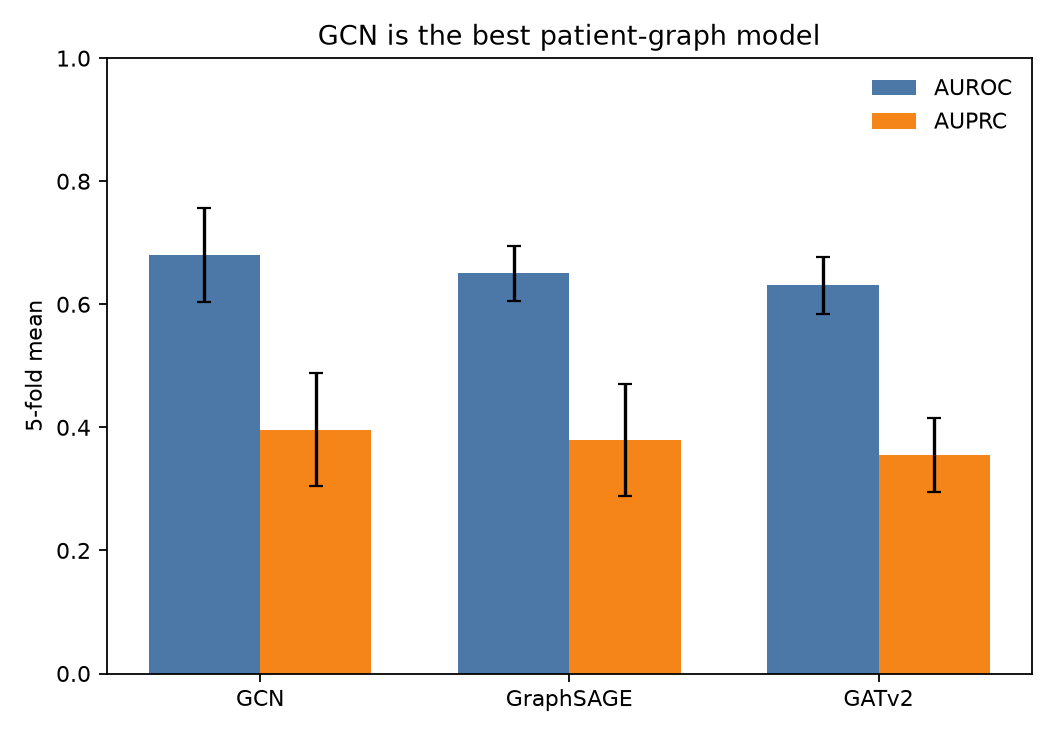

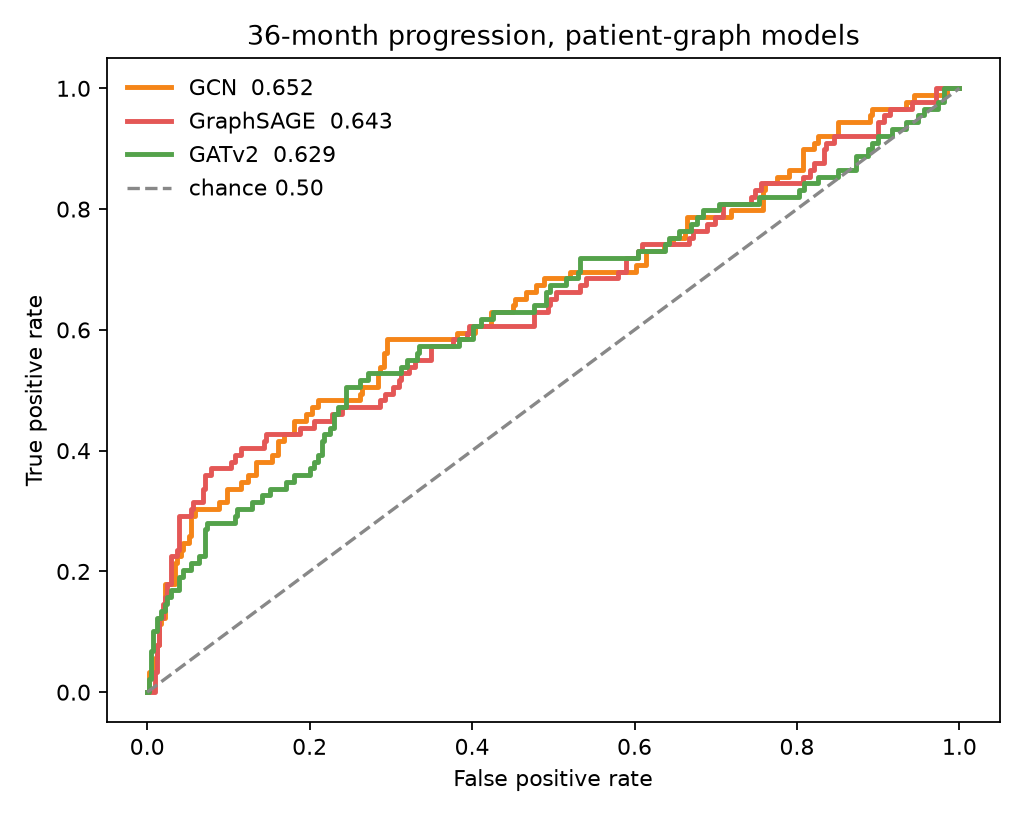

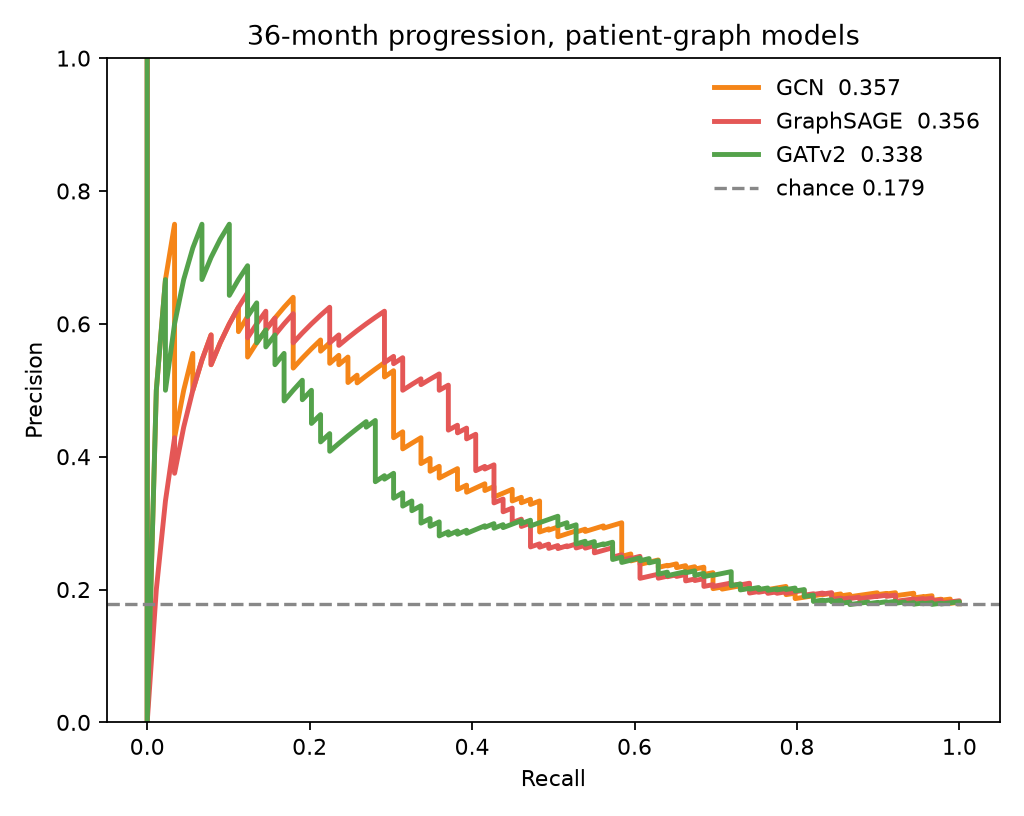

In [1]:
from IPython.display import Image, display
display(Image('outputs/gnn_benchmark_36m/graph_models_bars.png'))
display(Image('outputs/gnn_benchmark_36m/graph_models_roc.png'))
display(Image('outputs/gnn_benchmark_36m/graph_models_pr.png'))


## Symbolic reasoning: how a cause chain is chosen

After GCN scores a patient, we ask which path in that patient's graph pushed the score.

Two different numbers are involved. They are not the same thing.

1. **Patient probability.** GCN's chance that this patient progressed by 36 months. Example: 0.95 means the model thinks progression by 36 months is very likely.
2. **Edge importance.** GNNExplainer looks at the edges that are already stored and gives each one a score between 0 and 1. This is not the probability that the biology is true. The edge is already a fact in the graph. The score says how much that edge mattered for this prediction.

A cause chain has to be a real walk:

patient → tumour sample → an altered gene → a drug, pathway, or disease

One extra gene is allowed in the middle when PrimeKG links the altered gene to a partner, and that partner links to the drug, pathway, or disease. We do not invent edges.

The **path score** is the average of the edge-importance scores along that walk. For each explained patient we keep the walk with the highest average. The two examples below are real outputs for patients who did progress and whom GCN scored above 0.85.


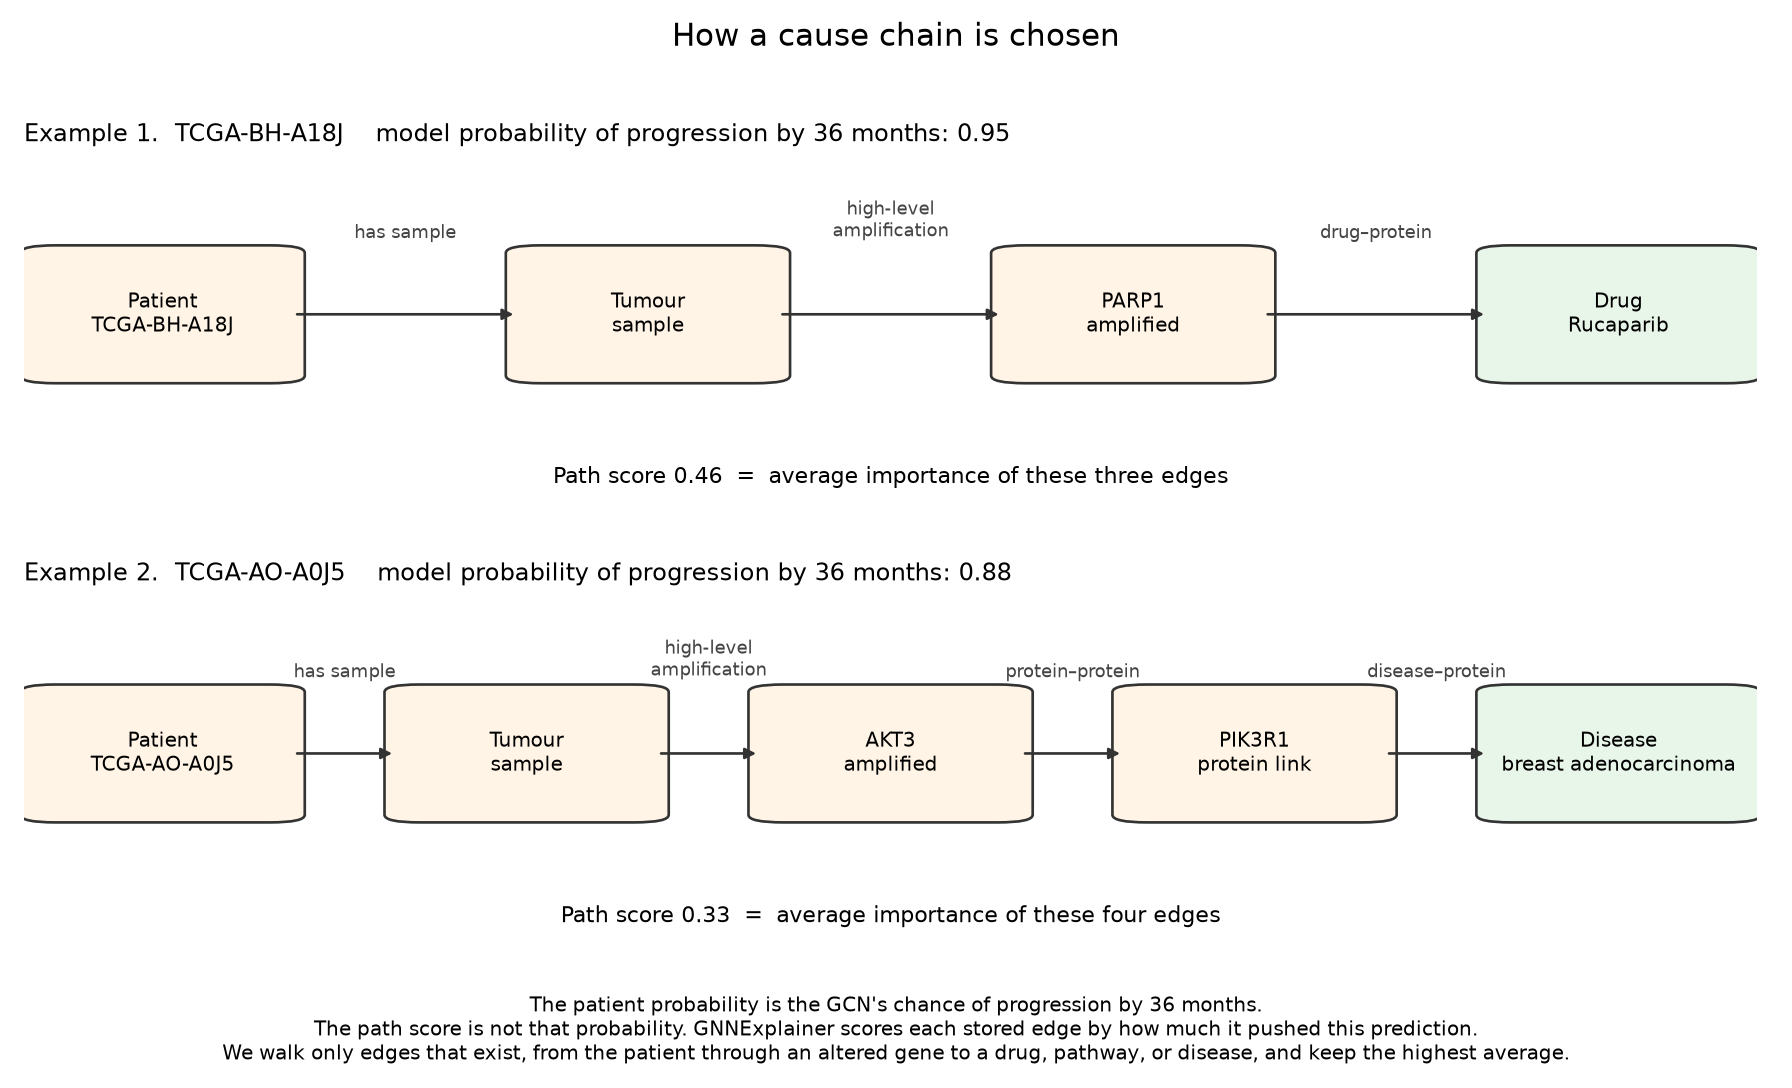

In [1]:
from IPython.display import Image, display
display(Image('outputs/gnn_benchmark_36m/cause_chains.png'))


### How to read the two examples

**TCGA-BH-A18J.** GCN's probability of progression by 36 months is **0.95**. The top chain is:

patient → tumour sample → **PARP1**, high-level amplification → drug **Rucaparib**

Rucaparib is a PARP inhibitor, so the chain is a real drug–protein link from the amplified gene, not a sentence we wrote in. The path score is **0.46**, the average importance of those three edges.

**TCGA-AO-A0J5.** GCN's probability is **0.88**. The chain we show is:

patient → tumour sample → **AKT3**, high-level amplification → protein **PIK3R1** → disease **breast adenocarcinoma**

The path score is **0.33**. AKT3 and PIK3R1 sit on the same PI3K signalling neighbourhood, and the disease node is the breast-cancer node PrimeKG actually connects. The path score is lower than the patient probability because it averages edge importance. It is not a second chance of recurrence.

These chains explain a prediction. They are not a claim that the graph has replaced stage and subtype, and they are not a treatment recommendation.
